In [1]:
#Decision Tree (DT) Hands on - regression - dept-investment-profit pred.
#import libraries
import pandas as pd



In [2]:
#reading the data file
dataset=pd.read_csv("50_Startups.csv")


In [3]:
#just to display dataset
dataset


,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94
5,131876.90,99814.71,362861.36,New York,156991.12
6,134615.46,147198.87,127716.82,California,156122.51
7,130298.13,145530.06,323876.68,Florida,155752.60
8,120542.52,148718.95,311613.29,New York,152211.77
9,123334.88,108679.17,304981.62,California,149759.96


In [4]:
#understand two set of variables X_train and x_train (case sensitives - holding two diff sets)

In [5]:
#categorical data is present - nominal (by name - state name)
#expanding columns - as machine understanding - one hot encoding
dataset=pd.get_dummies(dataset)


In [6]:
dataset

,R&D Spend,Administration,Marketing Spend,Profit,State_California,State_Florida,State_New York
0,165349.20,136897.80,471784.10,192261.83,0,0,1
1,162597.70,151377.59,443898.53,191792.06,1,0,0
2,153441.51,101145.55,407934.54,191050.39,0,1,0
3,144372.41,118671.85,383199.62,182901.99,0,0,1
4,142107.34,91391.77,366168.42,166187.94,0,1,0
5,131876.90,99814.71,362861.36,156991.12,0,0,1
6,134615.46,147198.87,127716.82,156122.51,1,0,0
7,130298.13,145530.06,323876.68,155752.60,0,1,0
8,120542.52,148718.95,311613.29,152211.77,0,0,1
9,123334.88,108679.17,304981.62,149759.96,1,0,0


In [7]:
#droping first column - to avoid repetition
dataset1=pd.get_dummies(dataset,dtype=int,drop_first=True)

In [8]:
dataset1

,R&D Spend,Administration,Marketing Spend,Profit,State_California,State_Florida,State_New York
0,165349.20,136897.80,471784.10,192261.83,0,0,1
1,162597.70,151377.59,443898.53,191792.06,1,0,0
2,153441.51,101145.55,407934.54,191050.39,0,1,0
3,144372.41,118671.85,383199.62,182901.99,0,0,1
4,142107.34,91391.77,366168.42,166187.94,0,1,0
5,131876.90,99814.71,362861.36,156991.12,0,0,1
6,134615.46,147198.87,127716.82,156122.51,1,0,0
7,130298.13,145530.06,323876.68,155752.60,0,1,0
8,120542.52,148718.95,311613.29,152211.77,0,0,1
9,123334.88,108679.17,304981.62,149759.96,1,0,0


In [9]:
#above code not dropping first column as version change, so modified as follows
import pandas as pd
dataset=pd.read_csv("50_Startups.csv")
dataset
# Convert categorical variables into dummy/indicator variables and drop the first category.
dataset=pd.get_dummies(dataset,dtype=int,drop_first=True)

In [10]:
dataset

,R&D Spend,Administration,Marketing Spend,Profit,State_Florida,State_New York
0,165349.20,136897.80,471784.10,192261.83,0,1
1,162597.70,151377.59,443898.53,191792.06,0,0
2,153441.51,101145.55,407934.54,191050.39,1,0
3,144372.41,118671.85,383199.62,182901.99,0,1
4,142107.34,91391.77,366168.42,166187.94,1,0
5,131876.90,99814.71,362861.36,156991.12,0,1
6,134615.46,147198.87,127716.82,156122.51,0,0
7,130298.13,145530.06,323876.68,155752.60,1,0
8,120542.52,148718.95,311613.29,152211.77,0,1
9,123334.88,108679.17,304981.62,149759.96,0,0


In [11]:
dataset1

,R&D Spend,Administration,Marketing Spend,Profit,State_California,State_Florida,State_New York
0,165349.20,136897.80,471784.10,192261.83,0,0,1
1,162597.70,151377.59,443898.53,191792.06,1,0,0
2,153441.51,101145.55,407934.54,191050.39,0,1,0
3,144372.41,118671.85,383199.62,182901.99,0,0,1
4,142107.34,91391.77,366168.42,166187.94,0,1,0
5,131876.90,99814.71,362861.36,156991.12,0,0,1
6,134615.46,147198.87,127716.82,156122.51,1,0,0
7,130298.13,145530.06,323876.68,155752.60,0,1,0
8,120542.52,148718.95,311613.29,152211.77,0,0,1
9,123334.88,108679.17,304981.62,149759.96,1,0,0


In [12]:
#to display columns, and we can use to copy paste field names
dataset.columns

Index(['R&D Spend', 'Administration', 'Marketing Spend', 'Profit',
       'State_Florida', 'State_New York'],
      dtype='object')

In [13]:
#spliting input and output varialbes,
#output variable is profit, rest all inputs
#assigning input varialbes to 'independent' variable 
independent=dataset[['R&D Spend', 'Administration', 'Marketing Spend', 
       'State_Florida', 'State_New York']]


In [14]:
independent

,R&D Spend,Administration,Marketing Spend,State_Florida,State_New York
0,165349.20,136897.80,471784.10,0,1
1,162597.70,151377.59,443898.53,0,0
2,153441.51,101145.55,407934.54,1,0
3,144372.41,118671.85,383199.62,0,1
4,142107.34,91391.77,366168.42,1,0
5,131876.90,99814.71,362861.36,0,1
6,134615.46,147198.87,127716.82,0,0
7,130298.13,145530.06,323876.68,1,0
8,120542.52,148718.95,311613.29,0,1
9,123334.88,108679.17,304981.62,0,0


In [15]:
#get output varialbe in 'dependent' variable
dependent=dataset[['Profit']]

In [16]:
dependent

,Profit
0,192261.83
1,191792.06
2,191050.39
3,182901.99
4,166187.94
5,156991.12
6,156122.51
7,155752.60
8,152211.77
9,149759.96


In [17]:
#now divide train set and test set
from sklearn.model_selection import train_test_split
#train 80%, test 20%
x_train,x_test,y_train,y_test=train_test_split(independent, dependent, test_size=0.20, random_state=0)

In [36]:
#now create model using training set
from sklearn.tree import DecisionTreeRegressor
#regressor=DecisionTreeRegressor() #1st -method - default 95%
#regressor=DecisionTreeRegressor(criterion='friedman_mse',splitter='best') #2nd method-97%
regressor=DecisionTreeRegressor(criterion='friedman_mse',splitter='random') #3rd method-82%%
regressor.fit(x_train,y_train)  #model created by this fit command

DecisionTreeRegressor(criterion='friedman_mse', splitter='random')

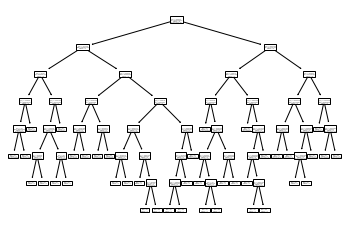

In [27]:
import matplotlib.pyplot as plt
from sklearn import tree
tree.plot_tree(regressor)
plt.show()

In [37]:
#start evaluating model
#to find the evaluation metrics on the input test data
y_pred=regressor.predict(x_test)

In [38]:
# to know r square metric - diff between actual o/p value of (x_test)-i.e y_test and predicted value of (x_test) - that is y_predicted
from sklearn.metrics import r2_score
r_score=r2_score(y_test,y_pred)

In [39]:
#printing r square ---> if nearly 1 , good model.  if near to 0, bad model
r_score


0.8269352906728374